In [11]:
import cv2
import h5py
import json 
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.figure import Figure
from matplotlib.collections import PolyCollection
import os
from pathlib import Path
import numpy as np
import matplotlib.image as mpimg

import panel as pn 

In [3]:
def mark_mirrors_on_img(img_path, points_list, color):
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    ax.imshow(img_rgb)

    for points in points_list:
        # === Polygon na podstawie 4 współrzędnych ===
        polygon = patches.Polygon(
                points,
                closed=True,
                linewidth=2,
                edgecolor=color,
                facecolor=color,
                alpha=0.3  # przezroczystość wypełnienia
            )
        ax.add_patch(polygon)

    plt.tight_layout()
    plt.show()

def show_img(img_path, ax):
    img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_axis_off()


In [4]:
test_img_json_path =  "/media/pgliwny/ADATA HD3304/Computer_vision_for_MAGIC/data/img_with_annomarly.json"
with open(test_img_json_path) as f:
    json_metadata_list = json.load(f)

print(json_metadata_list[0])
print(len(json_metadata_list))

{'file': 'image_2024-05-06_1000.jpg', 'marked_mirrors': [152, 176, 189, 190, 191, 192, 193, 209]}
16


In [5]:
IMG_DIR_PATH = Path("/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam")
file_path_list = [IMG_DIR_PATH / obj["file"] for obj in json_metadata_list] 
print(file_path_list[:3])

[PosixPath('/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1000.jpg'), PosixPath('/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1100.jpg'), PosixPath('/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1400.jpg')]


/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1000.jpg
/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1100.jpg
/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1400.jpg
/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam/image_2024-05-06_1500.jpg


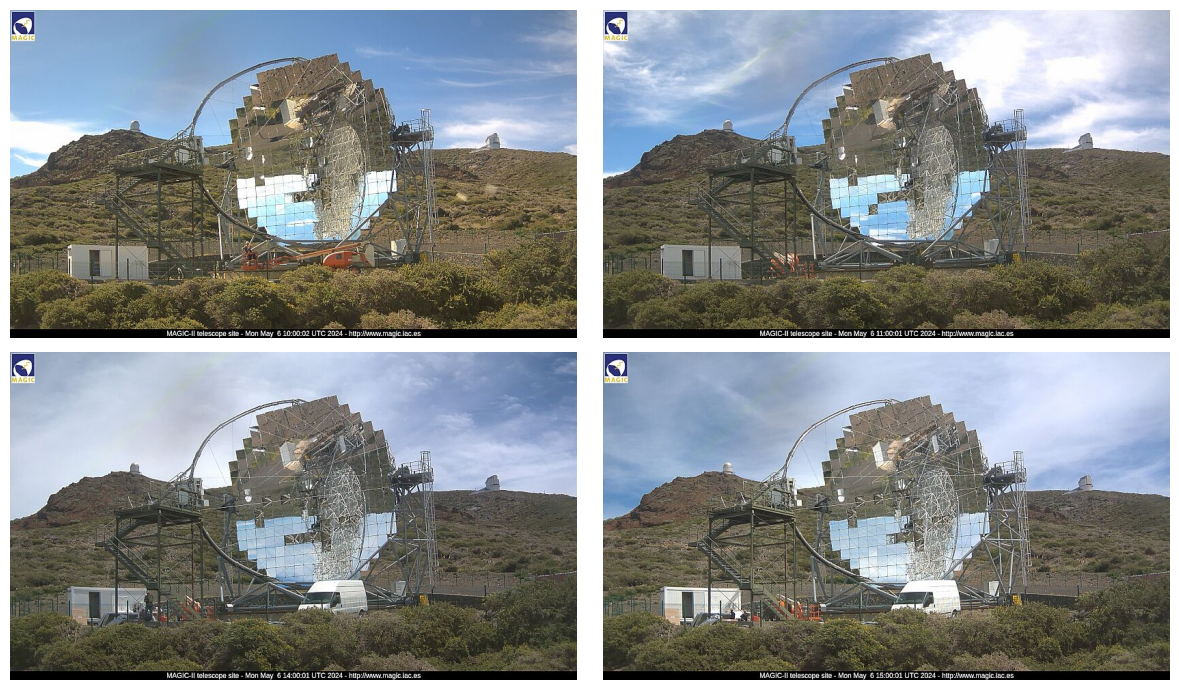

In [6]:
IMG_DIR_PATH = Path("/media/pgliwny/ADATA HD3304/Computer_Vision_system/data/MAGIC/webcam")

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
axes = ax.flatten()
for i, obj in enumerate(json_metadata_list[:4]):
    file_name = obj['file']
    img_path = IMG_DIR_PATH / file_name
    print(img_path)
    if img_path.exists():
        show_img(img_path, axes[i])

plt.tight_layout()
plt.show()

Column
    [0] IntSlider(end=15, label='klatka', name='klatka')
    [1] ParamFunction(function, _pane=Column, defer_load=False)
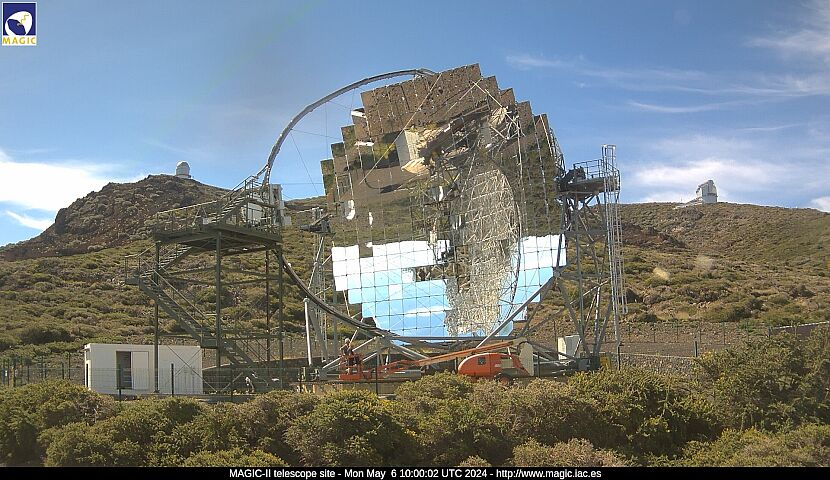

In [7]:
pn.extension()

files = sorted(file_path_list)
slider = pn.widgets.IntSlider(name="klatka", start=0, end=len(files)-1)

@pn.depends(i=slider)
def show(i):
    return pn.Column(
        pn.pane.Image(files[i], width=830),
        pn.pane.Markdown(f"`{files[i].name}`"),
    )

pn.Column(slider, show)

Column
    [0] IntSlider(end=15, label='klatka', name='klatka')
    [1] ParamFunction(function, _pane=Matplotlib, defer_load=False)
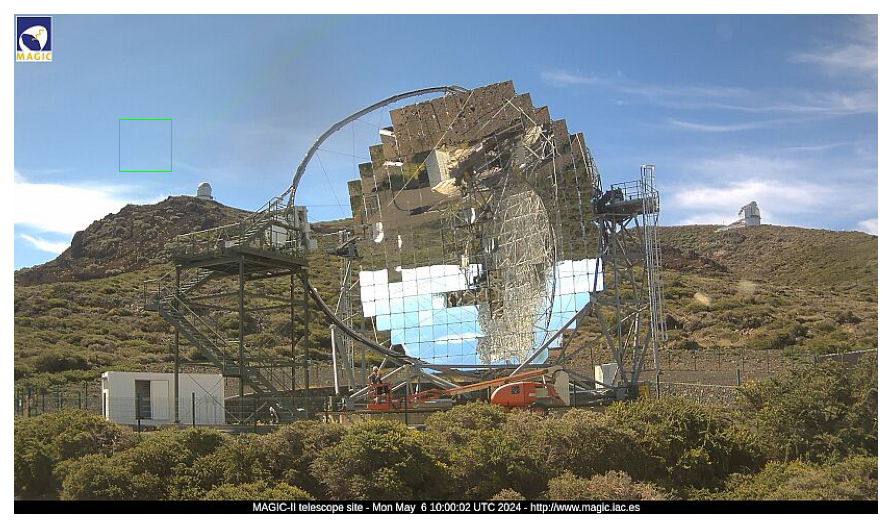

In [13]:
pn.extension()

files = sorted(file_path_list)
slider = pn.widgets.IntSlider(name="klatka", start=0, end=len(files)-1)

x0, y0, size = 100, 100, 50
rect = np.array([
    [x0,        y0       ],
    [x0 + size, y0       ],
    [x0 + size, y0 + size],
    [x0,        y0 + size],
])

polys = [rect]          # lista wielokątów — na razie jeden

@pn.depends(i=slider)
def show(i):
    fig = Figure(figsize=(6, 5), dpi=100)
    ax = fig.subplots()
    ax.imshow(mpimg.imread(files[i]), cmap="gray")
    ax.add_collection(PolyCollection(
        polys, facecolors="none", edgecolors="lime", linewidths=0.5))
    ax.set_axis_off()
    fig.tight_layout(pad=0)
    return pn.pane.Matplotlib(fig, tight=True) 

pn.Column(slider, show)